# Circular regression with Unwrap (R)

A minimal, fully self-contained introduction, in R, to the circular
regression machinery of `unwrap`: individual angular observations,
with both the von Mises mean direction and the concentration modeled
as functions of a continuous predictor, and all angles in
**radians**. The notebook generates synthetic angular data, fits a
`brms` von Mises model through the repository's custom
`unwrap_von_mises` family, and checks the posterior — all in one
sitting, with no external data and no downloads.

This is the **first R notebook to run** if you are new to the R
examples: it is the cheapest of the R notebooks to run end to end. A
matching version of the same tutorial lives in
`notebooks/circular_regression.ipynb`.


## Setup

Set up the R side once: the [R setup](../getting-started-r.md) page
installs the CRAN packages, CmdStan, and the Jupyter R kernel against
the pinned `renv.lock` versions. The first code cell below re-checks
the environment and stops with a pointer to the setup page if the
one-time setup has not been run; on a set-up machine it is a no-op.


In [1]:
# Setup: check that this notebook's stack is available. The examples
# are verified against the pinned package set recorded in renv.lock, so
# this cell deliberately does not auto-install: an unpinned install
# could silently drift from the verified set. Run the one-time setup on
# the R setup page first (docs/getting-started-r.md).

required <- c("brms", "posterior", "loo", "circular", "ggplot2", "ragg")
missing <- required[!vapply(required, requireNamespace, logical(1),
  quietly = TRUE)]
if (length(missing))
  stop("Missing R package(s): ", paste(missing, collapse = ", "),
       " - run the one-time setup on the R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

cmdstan_ok <- tryCatch(
  dir.exists(as.character(cmdstanr::cmdstan_path())),
  error = function(e) FALSE)
if (!cmdstan_ok)
  stop("cmdstanr/CmdStan is not available - run the one-time setup on the",
       " R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

In [2]:
suppressPackageStartupMessages({
    library(brms)
    library(posterior)
    library(loo)
    library(circular)
    library(ggplot2)
})

# The repository's R helpers (custom brms family + circular statistics)
# live next to the notebook; make them reachable regardless of the
# kernel's working directory.
repo_root <- if (file.exists(file.path("..", "R", "unwrap_family.R"))) ".." else
    if (file.exists(file.path("R", "unwrap_family.R"))) "." else
    stop("Run this notebook from notebooks_r/ or from the repository root.")
source(file.path(repo_root, "R", "unwrap_family.R"))
source(file.path(repo_root, "R", "unwrap_functions.R"))

# The figure code writes to the repository-relative figures directory.
FIG_DIR <- file.path(repo_root, "figures", "circular_regression")
dir.create(FIG_DIR, recursive = TRUE, showWarnings = FALSE)
theme_set(theme_minimal(base_size = 12))

# Without X11/cairo (most server R installs) the default device cannot
# rasterise, so each figure renders to a PNG through ragg and displays
# inline; a vector PDF is saved alongside as the portable copy.
show_figure <- function(plot, name, width, height, res = 110) {
  file <- file.path(FIG_DIR, paste0(name, ".png"))
  ragg::agg_png(file, width = width, height = height, units = "in",
                res = res)
  print(plot)
  invisible(dev.off())
  IRdisplay::display_png(file = file)
  invisible(NULL)
}

SEED <- 42
# CI runs with shortened sampling (the committed outputs use the full
# budget); local runs always use the full budget.
quick_run <- Sys.getenv("UNWRAP_R_QUICK") == "1"
CHAINS <- 4L
ITER <- if (quick_run) 750L else 1000L
WARMUP <- if (quick_run) 375L else 500L

c(R = as.character(getRversion()),
  brms = as.character(packageVersion("brms")),
  cmdstanr = as.character(packageVersion("cmdstanr")),
  posterior = as.character(packageVersion("posterior")),
  loo = as.character(packageVersion("loo")),
  circular = as.character(packageVersion("circular")),
  ggplot2 = as.character(packageVersion("ggplot2")))

Loading required package: cmdstanr



This is cmdstanr version 0.9.0



- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr



- CmdStan path: /home/jake/.cmdstan/cmdstan-2.40.0



- CmdStan version: 2.40.0



R          brms      cmdstanr     posterior           loo 
      "4.5.3"      "2.23.0"       "0.9.0"       "1.7.1" "2.10.1.9000" 
     circular       ggplot2 
      "0.5.2"       "4.0.3"

## Figure style

Figures render inline and are saved as vector (PDF) files under `figures/circular_regression/`.

## 1. Generate synthetic angular data

Draw from a von Mises model with known mean and concentration — a
test-bed: because the true relationship is known, we can check that
the posterior recovers it. For predictor $x \in (-1, 1)$, the
generating mean is $\mu = x$ (wrapped to $[-\pi,\pi)$) and the
concentration is $\kappa = \operatorname{softplus}(2 + 0.5x)$:
larger concentration means less angular dispersion. These values
create a simple example; they do not prescribe priors for a real
dataset. Sampling uses `circular::rvonmises`, the standard von Mises
sampler.


In [3]:
set.seed(SEED)
n_samples <- 200
x <- runif(n_samples, min = -1, max = 1)

# Generating model (known ground truth): mu = 0 + 1 * x wrapped, and
# kappa = softplus(2 + 0.5 * x) - the concentration on the natural
# scale; the model below recovers the pre-softplus values (2 and 0.5).
mu_true <- mod_circular(x)
kappa_true <- softplus(2 + 0.5 * x)
# circular 0.5.x samplers take scalar mu and kappa plus a control list;
# draw on the default [0, 2*pi) domain and wrap back to the model's
# (-pi, pi] convention. (These helpers are reused in the PPC cell below.)
vmu <- function(m) circular::circular(
    m, units = "radians", template = "none", modulo = "2pi")
vm_ctrl <- list(units = "radians", template = "none", modulo = "2pi")
y <- vapply(
    seq_len(n_samples),
    function(i) as.numeric(circular::rvonmises(1,
        mu = vmu(mu_true[i]),
        kappa = kappa_true[i],
        control.circular = vm_ctrl)),
    numeric(1))
y <- mod_circular(y)

data <- data.frame(x = x, y = y)
stopifnot(all(data$y <= pi & data$y >= -pi))
head(data)

,x,y
,<dbl>,<dbl>
1,0.8296121,0.9886201
2,0.8741508,0.2938535
3,-0.4277209,-1.1996958
4,0.6608953,0.7222447
5,0.2834910,1.0779473
6,0.0381919,0.2251189


## 2. Specify the model

`brms`'s formula interface describes the regression; the circular
nature is carried by the custom `unwrap_von_mises` family, which keeps
the mean direction on the circle through a periodic (modulo) link.

`y ~ x` describes the mean direction; `kappa ~ x` describes
concentration. Softplus keeps the concentration positive, so the
concentration coefficients live on the **pre-softplus** scale. The
mean intercept has an approximately uniform circular prior; the slope
priors assume this predictor's scale of $-1$ to $1$. Adapt these
choices to your scientific question and check prior predictive
behavior when analyzing real data.


In [4]:
# y ~ x: mean direction; kappa ~ x: concentration
form_vonmises <- bf(y ~ x, kappa ~ x, family = unwrap_von_mises)

prior_vonmises <- (
  # effectively uniform circular prior on the mean intercept: von Mises
  # (0, kappa) with kappa = double-precision machine epsilon, the same
  # CircularUniformPrior() value the Python twin uses.
  prior("unwrap_von_mises(0, 2.220446049250313e-16)", class = "Intercept", dpar = "mu") +
  # slope priors assume this predictor's scale of -1 to 1
  prior("normal(0, pi()/2)", class = "b", dpar = "mu") +
  prior("normal(2.0, 0.5)", class = "Intercept", dpar = "kappa") +
  prior("normal(0.0, 1.0)", class = "b", dpar = "kappa")
)
prior_vonmises

prior,class,coef,group,resp,dpar,nlpar,lb,ub,tag,source
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
"unwrap_von_mises(0, 2.220446049250313e-16)",Intercept,,,,,,NA,NA,,user
"normal(0, pi()/2)",b,,,,,,NA,NA,,user
"normal(2.0, 0.5)",Intercept,,,,kappa,,NA,NA,,user
"normal(0.0, 1.0)",b,,,,kappa,,NA,NA,,user


## 3. Fit and inspect sampling

`brm()` runs NUTS via Stan. Four chains with 500 warmup iterations
and 500 retained draws each keep this introduction manageable — the
budget is a convenience for a toy dataset, not a universal sampling
prescription.

Inspect the divergence count first — it must be 0 for the other
diagnostics to mean anything. $\hat{R} \approx 1$ on the
*unwrapped* intercept (directions are periodic, so chain draws are
centered and compared on the line before taking R-hat: the circular
analogue of the naive statistic) and effective sample sizes well above
400. The true mean direction used to generate the data should be
recoverable from the posterior; increase sampling or revise the model
if the diagnostics are unsatisfactory.


In [5]:
fit <- unwrap_load_fit_cache("circular_regression_fit_v2", SEED, ITER, WARMUP)
if (is.null(fit)) {
  fit <- brm(
      form_vonmises, data = data,
      stanvars = stan_unwrap_fun + modulo_circular_fun,
      prior = prior_vonmises,
      chains = CHAINS, iter = ITER, warmup = WARMUP, cores = CHAINS,
      seed = SEED, control = list(adapt_delta = 0.9),
      backend = "cmdstanr")
  unwrap_save_fit_cache("circular_regression_fit_v2", fit, SEED, ITER, WARMUP)
}
# NUTS divergences. Not every brms/cmdstanr combination keeps the
# per-iteration divergence flag in the fit object, so probe for it and
# report what the fit object actually carries (the R-hat and ESS values
# below are the primary convergence checks either way).
divergences <- tryCatch({
  div_flags <- lapply(fit$fit@sim$samples, function(ch) ch[["divergent"]])
  if (any(vapply(div_flags, is.null, logical(1)))) NA_real_
  else sum(unlist(div_flags))
}, error = function(e) NA_real_)
if (is.na(divergences)) {
    cat("Divergences: not retained in this fit object (see R-hat/ESS below).\n")
} else {
    cat("Divergences:", divergences, "\n")
}

parameters <- c("b_Intercept", "b_x", "b_kappa_Intercept", "b_kappa_x")
draws <- posterior::as_draws_df(fit, variables = parameters)
stopifnot(all(vapply(draws, function(v) all(is.finite(v)), logical(1))))

# Convergence: R-hat (unwrapped for the circular intercept) and ESS,
# computed across the chains on the [iteration x chain] draws.
n_chains <- max(draws[[".chain"]])
draw_split <- lapply(parameters, function(p) {
    o <- order(draws[[".chain"]], draws[[".iteration"]])
    matrix(as.numeric(draws[[p]][o]), ncol = n_chains)
})
names(draw_split) <- parameters
rhat_values <- c(b_Intercept = unname(Rhat_unwrap(draw_split[[1]], method = "mean")),
                 unname(vapply(draw_split[2:4], posterior::rhat, numeric(1))))
names(rhat_values) <- parameters
ess_values <- vapply(parameters, function(p) posterior::ess_bulk(draw_split[[p]]), numeric(1))

# Posterior summary. The intercept is circular, so its location is the
# circular mean and its spread the circular standard deviation - the
# R analogue of the Python tutorial's circular_summary().
circ_mean <- function(a) atan2(mean(sin(a)), mean(cos(a)))
circ_sd <- function(a, m) sqrt(-2 * log(Mod(mean(exp(1i * (a - m))))))
m_int <- circ_mean(draws$b_Intercept)
summary_frame <- data.frame(
    parameter = parameters,
    mean = c(m_int, mean(draws$b_x), mean(draws$b_kappa_Intercept),
             mean(draws$b_kappa_x)),
    sd = c(circ_sd(draws$b_Intercept, m_int), sd(draws$b_x),
           sd(draws$b_kappa_Intercept), sd(draws$b_kappa_x)),
    rhat = round(rhat_values, 4),
    ess = round(ess_values, 1),
    # generating values (kappa on the pre-softplus scale)
    truth = c(0, 1, 2, 0.5),
    row.names = NULL, check.names = FALSE)
summary_frame

Start sampling



Running MCMC with 4 parallel chains...

Chain 1 Iteration:   1 / 1000 [  0%]  (Warmup) 
Chain 2 Iteration:   1 / 1000 [  0%]  (Warmup) 
Chain 3 Iteration:   1 / 1000 [  0%]  (Warmup) 
Chain 3 Iteration: 100 / 1000 [ 10%]  (Warmup) 
Chain 4 Iteration:   1 / 1000 [  0%]  (Warmup) 
Chain 4 Iteration: 100 / 1000 [ 10%]  (Warmup) 
Chain 1 Iteration: 100 / 1000 [ 10%]  (Warmup) 
Chain 1 Iteration: 200 / 1000 [ 20%]  (Warmup) 
Chain 1 Iteration: 300 / 1000 [ 30%]  (Warmup) 
Chain 2 Iteration: 100 / 1000 [ 10%]  (Warmup) 
Chain 4 Iteration: 200 / 1000 [ 20%]  (Warmup) 
Chain 1 Iteration: 400 / 1000 [ 40%]  (Warmup) 
Chain 2 Iteration: 200 / 1000 [ 20%]  (Warmup) 
Chain 3 Iteration: 200 / 1000 [ 20%]  (Warmup) 
Chain 1 Iteration: 500 / 1000 [ 50%]  (Warmup) 
Chain 1 Iteration: 501 / 1000 [ 50%]  (Sampling) 
Chain 2 Iteration: 300 / 1000 [ 30%]  (Warmup) 
Chain 3 Iteration: 300 / 1000 [ 30%]  (Warmup) 
Chain 4 Iteration: 300 / 1000 [ 30%]  (Warmup) 
Chain 1 Iteration: 600 / 1000 [ 60%]  (Samplin

Loading required namespace: rstan



Divergences: not retained in this fit object (see R-hat/ESS below).


parameter,mean,sd,rhat,ess,truth
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
b_Intercept,-0.07527971,0.05250391,1.0001,2332.7,0.0
b_x,1.05524198,0.08873374,1.0041,2306.6,1.0
b_kappa_Intercept,2.27807708,0.20031205,1.0048,2329.0,2.0
b_kappa_x,0.59774087,0.36952831,1.0009,2071.9,0.5


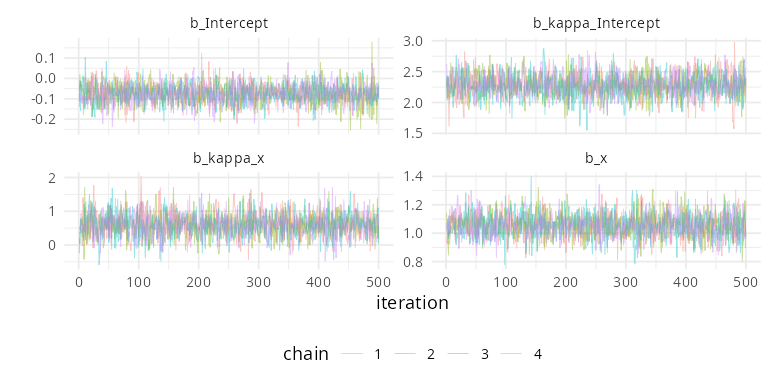

In [6]:
# Posterior traces for the four parameters (the figure is saved under
# figures/circular_regression/): one line per chain against the
# post-warmup iteration, one panel per parameter - the same view as the
# Python tutorial's traceplot.
draws_df <- posterior::as_draws_df(fit, variables = parameters)
trace_df <- do.call(rbind, lapply(seq_along(parameters), function(k)
    data.frame(parameter = parameters[k],
               iteration = as.integer(draws_df[[".iteration"]]),
               value = as.numeric(draws_df[[parameters[k]]]),
               chain = factor(as.integer(draws_df[[".chain"]])))))
p_trace <- ggplot(trace_df, aes(x = iteration, y = value, colour = chain)) +
    geom_line(alpha = 0.4, linewidth = 0.3) +
    facet_wrap(~ parameter, scales = "free_y") +
    scale_color_discrete(name = "chain") +
    labs(x = "iteration", y = "") +
    theme(legend.position = "bottom")
ggsave(file.path(FIG_DIR, "trace.pdf"), p_trace, width = 7, height = 3.5)
show_figure(p_trace, "trace", 7, 3.5)

## 4. Interpret predictions on the circle

The prediction cell evaluates the von Mises mean direction and
concentration across a range of the predictor — the direct analogue of
a standard model-averaged prediction curve, but drawn on the circle.

Average predicted directions as unit vectors, not ordinary numbers:
angles near $-\pi$ and $\pi$ are neighbours, so the mean-direction
panel uses the circular mean of each grid point's posterior draws while
the second panel averages the (post-softplus) concentration draws.
These curves summarize the posterior; they are not uncertainty
intervals. The dashed generating curves are available only because this
dataset is simulated.

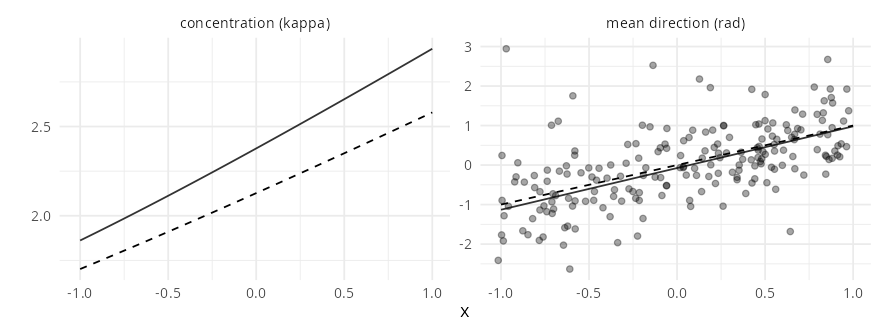

In [7]:
grid_x <- seq(-1, 1, length.out = 100)

# Posterior draws of the linear predictors: [grid x draws] matrices -
# row j / column d holds the draw-d linear predictor at grid point j.
lin_mu <- matrix(rep(draws_df$b_Intercept, each = length(grid_x)),
                 nrow = length(grid_x)) + outer(grid_x, draws_df$b_x)
lin_kappa <- matrix(rep(draws_df$b_kappa_Intercept, each = length(grid_x)),
                    nrow = length(grid_x)) + outer(grid_x, draws_df$b_kappa_x)

# Average the predicted directions as unit vectors (angles near +/-pi
# are neighbours), and average the concentration draws for the right-
# hand panel.
mean_direction <- atan2(apply(sin(lin_mu), 1, mean),
                        apply(cos(lin_mu), 1, mean))
concentration <- apply(softplus(lin_kappa), 1, mean)

obs_df <- data.frame(grid = data$x, value = data$y,
                     panel = "mean direction (rad)")
pred_df <- data.frame(
    grid = rep(grid_x, 2),
    value = c(mean_direction, concentration),
    panel = c(rep("mean direction (rad)", length(grid_x)),
              rep("concentration (kappa)", length(grid_x))))
p_pred <- ggplot(pred_df, aes(grid, value)) +
    geom_line(alpha = 0.8) +
    geom_point(data = obs_df, aes(grid, value),
               alpha = 0.35, position = position_jitter(width = 0.02, height = 0.15)) +
    geom_line(data = data.frame(grid = grid_x,
                                value = mod_circular(grid_x),
                                panel = "mean direction (rad)"),
              aes(grid, value), inherit.aes = FALSE,
              linetype = "dashed") +
    geom_line(data = data.frame(grid = grid_x,
                                value = softplus(2 + 0.5 * grid_x),
                                panel = "concentration (kappa)"),
              aes(grid, value), inherit.aes = FALSE,
              linetype = "dashed") +
    facet_wrap(~ panel, scales = "free_y") +
    labs(x = expression(x), y = "")
ggsave(file.path(FIG_DIR, "predictions.pdf"), p_pred, width = 8, height = 3)
show_figure(p_pred, "predictions", 8, 3)

## 5. Check posterior predictive behavior

Simulate new angles at the observed predictor values and compare the
observed mean resultant length (a circular concentration summary) with
that statistic in the replicated datasets. For a well-specified model
the two should match; a systematic mismatch (the predictive too narrow,
or the predicted mean shifted) signals misspecification, as in a
standard Gaussian GLM. This is one aggregate check: it can miss local
lack of fit and reflects variation in both mean direction and
concentration across $x$. For real data, add checks conditional on
predictors and relevant groups.

The fitted links are applied explicitly below (the modulo link for the
mean, softplus for the concentration) and the replicates are drawn with
`circular::rvonmises` — the same von Mises sampler used to generate the
data.

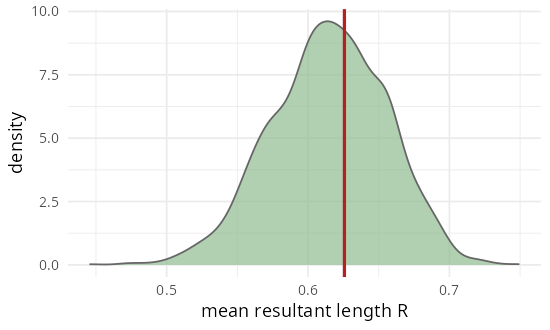

In [8]:
obs_x <- data$x
n_draws <- nrow(draws)

# The 0.5.x sampler draws one observation at a time (scalar mu/kappa),
# so replicate in a draw-by-observation nested loop (~2-4 min for the
# full posterior here).
replicated <- matrix(0, nrow = n_draws, ncol = length(obs_x))
for (d in seq_len(n_draws))
  for (i in seq_len(length(obs_x)))
    replicated[d, i] <- as.numeric(circular::rvonmises(1,
        mu = vmu(draws$b_Intercept[d] + draws$b_x[d] * obs_x[i]),
        kappa = softplus(draws$b_kappa_Intercept[d] +
                         draws$b_kappa_x[d] * obs_x[i]),
        control.circular = vm_ctrl))
replicated <- mod_circular(replicated)
# Replicate the data at the observed x values; the figure below compares
# the observed mean resultant length against the replicated one.
replicated_R <- apply(exp(1i * replicated), 1, function(z) Mod(mean(z)))
observed_R <- Mod(mean(exp(1i * data$y)))
stopifnot(all(is.finite(replicated_R)))

p_ppc <- ggplot(data.frame(replicated_R), aes(replicated_R)) +
    geom_density(alpha = 0.7, fill = "darkseagreen", colour = "grey40") +
    geom_vline(xintercept = observed_R, colour = "firebrick", linewidth = 1) +
    labs(x = "mean resultant length R", y = "density")
ggsave(file.path(FIG_DIR, "ppc.pdf"), p_ppc, width = 5, height = 3)
show_figure(p_ppc, "ppc", 5, 3)

## Next steps

The beetle, zebra, and locust notebooks build on the same setup to
explore more complex designs — hierarchical structure, treatments,
and mixture likelihoods. When analyzing your own data, start by
defining the scientific estimand, the angular reference direction,
and the sampling structure. This tutorial assumes independent
observations and does not address hierarchical dependence or
mixtures.

The standalone R scripts (`R/brms_example.R`, `R/unwrap_functions.R`)
that this notebook builds on are documented on the [R and
MATLAB](../languages.md) page.
